In [1]:
from dataset import df
import pandas as pd

df

,latitude,longitude,sand,elcosp,slope,landcover,orgc,inorgc,silt_clay,phaq,bedrock,soil_type,ecoregion,rock_fragments,depth
0,15.375747,-92.924872,53.411810,0.117950,0.153699,10.0,15.868971,0.000000,46.588190,5.917957,rocas_metamorficas,FLUVISOL EUTRICO,1.0,0.001939,0_5
1,15.375747,-92.924872,33.299825,0.049220,0.153699,10.0,8.683302,0.000000,66.700175,5.854219,rocas_metamorficas,FLUVISOL EUTRICO,1.0,0.011414,15_30
2,15.375747,-92.924872,48.878541,0.102914,0.153699,10.0,14.303404,0.000000,51.121459,5.902915,rocas_metamorficas,FLUVISOL EUTRICO,1.0,0.000931,5_15
3,15.933933,-93.805531,83.328428,0.112064,0.153699,17.0,10.530031,0.000000,16.671572,5.824141,rocas_metamorficas,REGOSOL EUTRICO,7.0,0.001939,0_5
4,15.933933,-93.805531,88.791135,0.018339,0.153699,17.0,6.114025,0.000000,11.208865,6.449995,rocas_metamorficas,REGOSOL EUTRICO,7.0,0.011414,15_30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10044,28.700932,-103.260435,68.286592,0.113175,0.912038,12.0,1.612308,163.076087,31.713408,8.675840,rocas_sedimentarias,REGOSOL CALCARICO,5.0,7.833180,15_30
10045,28.700932,-103.260435,67.685121,0.085524,0.912038,12.0,2.425957,163.076087,32.314879,8.726544,rocas_sedimentarias,REGOSOL CALCARICO,5.0,6.071739,5_15
10049,32.359091,-116.863987,59.221832,0.217659,2.340468,7.0,18.357349,0.000000,40.778168,6.280829,rocas_sedimentarias,VERTISOL CROMICO,5.0,20.874676,0_5
10050,32.359091,-116.863987,60.271647,0.093543,2.340468,7.0,14.050194,63.348584,39.728353,5.635044,rocas_sedimentarias,VERTISOL CROMICO,5.0,23.411763,15_30


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics.pairwise import haversine_distances
from math import radians
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch.nn import TripletMarginLoss
import random

# --- Configuration ---
# Path to your data file (replace with your actual path)
# DATA_FILE_PATH = 'your_soil_data.csv'
# For demonstration, we'll create a dummy DataFrame
N_SAMPLES = 100  # Number of soil samples for the dummy data
NEIGHBOR_RADIUS_KM = 10.0
EMBEDDING_DIM = 64  # Desired dimension for soil embeddings
LEARNING_RATE = 0.01
EPOCHS = 50 # Number of training epochs
TRIPLET_MARGIN = 1.0

# --- 1. Data Loading and Preprocessing ---
def load_and_preprocess_data(df):
    """
    Loads soil data, preprocesses features (scaling, one-hot encoding).
    If df_path is None, creates dummy data.
    """

    print("Original DataFrame head:")
    print(df.head())

    numerical_cols = ['sand', 'elcosp', 'slope', 'orgc', 'inorgc', 'silt_clay', 'phaq', 'rock_fragments']
    categorical_cols = ['landcover', 'soil_type', 'ecoregion', 'bedrock', 'depth']

    # Ensure all specified columns exist
    missing_num_cols = [col for col in numerical_cols if col not in df.columns]
    missing_cat_cols = [col for col in categorical_cols if col not in df.columns]
    if missing_num_cols:
        raise ValueError(f"Missing numerical columns: {missing_num_cols}")
    if missing_cat_cols:
        raise ValueError(f"Missing categorical columns: {missing_cat_cols}")

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
        ],
        remainder='passthrough' # Keep other columns (like lat/lon)
    )

    processed_features = preprocessor.fit_transform(df)
    
    # Get feature names after one-hot encoding for clarity (optional)
    ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
    all_feature_names = numerical_cols + list(ohe_feature_names)

    # Convert to DataFrame to easily separate features and coordinates
    # Note: The order of columns from ColumnTransformer can be tricky.
    # It's often easier to manage features and coordinates separately before this point
    # or reconstruct the DataFrame carefully.
    
    # For simplicity, we'll extract node features directly from the sparse matrix if it's sparse
    if hasattr(processed_features, "toarray"):
        node_features_np = processed_features.toarray()
    else:
        node_features_np = processed_features
        
    node_features = torch.tensor(node_features_np, dtype=torch.float)
    
    print(f"\nShape of processed node features: {node_features.shape}")
    return df, node_features

# --- 2. Graph Construction ---
def construct_graph(df, radius_km=NEIGHBOR_RADIUS_KM):
    """
    Constructs graph edges based on Haversine distance between lat/lon coordinates.
    """
    coords = df[['latitude', 'longitude']].values
    # Convert degrees to radians for Haversine distance
    coords_rad = np.array([[radians(lat), radians(lon)] for lat, lon in coords])

    # Calculate pairwise distances (multiply by Earth's radius in km)
    dist_matrix = haversine_distances(coords_rad) * 6371  # Earth radius in km

    edge_list = []
    num_nodes = len(df)
    for i in range(num_nodes):
        for j in range(i + 1, num_nodes): # Avoid self-loops and duplicate edges
            if dist_matrix[i, j] <= radius_km:
                edge_list.append([i, j])
                edge_list.append([j, i]) # Add edges in both directions for undirected graph

    if not edge_list:
        print("Warning: No edges were created. Check your radius_km or data distribution.")
        # Create a graph with no edges if none are found, to avoid errors later
        edge_index = torch.empty((2, 0), dtype=torch.long)
    else:
        edge_index = torch.tensor(edge_list, dtype=torch.long).t().contiguous()
    
    print(f"\nNumber of nodes: {num_nodes}")
    print(f"Number of edges (connections within {radius_km}km): {edge_index.shape[1]}")
    return edge_index

# --- 3. GNN Model Definition ---
class GCNEmbedder(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(GCNEmbedder, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.relu = nn.ReLU()
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.relu(x)
        x = self.conv2(x, edge_index)
        return x # These are the embeddings

# --- 4. Training ---
def train_gnn(data, model, epochs=EPOCHS, lr=LEARNING_RATE, margin=TRIPLET_MARGIN):
    """
    Trains the GNN model using a triplet loss.
    """
    optimizer = optim.Adam(model.parameters(), lr=lr)
    triplet_loss_fn = TripletMarginLoss(margin=margin)
    
    num_nodes = data.x.shape[0]
    if data.edge_index.shape[1] == 0:
        print("Skipping training as there are no edges in the graph.")
        return

    # Create an adjacency list for quick neighbor lookup
    adj = [[] for _ in range(num_nodes)]
    for i in range(data.edge_index.shape[1]):
        u, v = data.edge_index[0, i].item(), data.edge_index[1, i].item()
        adj[u].append(v)

    print("\nStarting GNN training...")
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        # Generate triplets: (anchor, positive, negative)
        anchors, positives, negatives = [], [], []
        
        # Iterate through nodes that have neighbors to act as anchors
        for anchor_idx in range(num_nodes):
            if not adj[anchor_idx]: # Skip nodes with no neighbors
                continue

            # Positive sample: a direct neighbor
            positive_idx = random.choice(adj[anchor_idx])

            # Negative sample: a node that is not the anchor and not its neighbor
            while True:
                negative_idx = random.randint(0, num_nodes - 1)
                if negative_idx != anchor_idx and negative_idx not in adj[anchor_idx]:
                    break
            
            anchors.append(anchor_idx)
            positives.append(positive_idx)
            negatives.append(negative_idx)

        if not anchors: # If no valid triplets could be formed (e.g., very sparse graph)
            print(f"Epoch {epoch+1}/{epochs}: No triplets generated, skipping batch.")
            continue

        # Get embeddings for all nodes
        all_embeddings = model(data.x, data.edge_index)

        # Select embeddings for anchors, positives, and negatives
        anchor_emb = all_embeddings[anchors]
        positive_emb = all_embeddings[positives]
        negative_emb = all_embeddings[negatives]
        
        loss = triplet_loss_fn(anchor_emb, positive_emb, negative_emb)
        loss.backward()
        optimizer.step()

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")
    print("Training finished.")

# --- Main Execution ---
if __name__ == '__main__':
    # 1. Load and preprocess data
    # Replace 'your_soil_data.csv' with the actual path to your data file
    # If you don't have a file, it will use dummy data.
    original_df, node_features = load_and_preprocess_data(df) 
                                                        # Example: load_and_preprocess_data('path/to/your/soil_data.csv')

    # 2. Construct graph
    edge_index = construct_graph(original_df, radius_km=NEIGHBOR_RADIUS_KM)

    # Create PyTorch Geometric Data object
    data = Data(x=node_features, edge_index=edge_index)

    # 3. Initialize GNN model
    in_channels = data.x.shape[1]
    hidden_channels = 128 # Can be tuned
    model = GCNEmbedder(in_channels, hidden_channels, EMBEDDING_DIM)
    print(f"\nGNN Model: {model}")

    # 4. Train the GNN
    # Ensure there are features and edges before training
    if data.x is not None and data.x.shape[0] > 0 and data.edge_index is not None:
         train_gnn(data, model, epochs=EPOCHS, lr=LEARNING_RATE, margin=TRIPLET_MARGIN)
    else:
        print("Skipping training due to missing data or graph components.")


    # 5. Generate and inspect embeddings (after training)
    model.eval() # Set model to evaluation mode
    with torch.no_grad(): # Disable gradient calculations
        final_embeddings = model(data.x, data.edge_index)
    
    print(f"\nShape of final soil embeddings: {final_embeddings.shape}")
    print("First 5 embeddings (rows):")
    print(final_embeddings[20:25])

    # Now `final_embeddings` contains the learned representations for each soil sample.
    # You can save these embeddings or use them for downstream tasks like finding
    # similar soils using cosine similarity or other distance metrics.
    # For example, to find soils similar to the first soil sample:
    # from sklearn.metrics.pairwise import cosine_similarity
    # similarities = cosine_similarity(final_embeddings[0].unsqueeze(0), final_embeddings)
    # sorted_indices = np.argsort(similarities[0])[::-1] # Sort by similarity
    # print(f"\nSoils most similar to soil 0: {sorted_indices[:5]}")


Original DataFrame head:
    latitude  longitude       sand    elcosp     slope  landcover       orgc  \
0  15.375747 -92.924872  53.411810  0.117950  0.153699       10.0  15.868971   
1  15.375747 -92.924872  33.299825  0.049220  0.153699       10.0   8.683302   
2  15.375747 -92.924872  48.878541  0.102914  0.153699       10.0  14.303404   
3  15.933933 -93.805531  83.328428  0.112064  0.153699       17.0  10.530031   
4  15.933933 -93.805531  88.791135  0.018339  0.153699       17.0   6.114025   

   inorgc  silt_clay      phaq             bedrock         soil_type  \
0     0.0  46.588190  5.917957  rocas_metamorficas  FLUVISOL EUTRICO   
1     0.0  66.700175  5.854219  rocas_metamorficas  FLUVISOL EUTRICO   
2     0.0  51.121459  5.902915  rocas_metamorficas  FLUVISOL EUTRICO   
3     0.0  16.671572  5.824141  rocas_metamorficas   REGOSOL EUTRICO   
4     0.0  11.208865  6.449995  rocas_metamorficas   REGOSOL EUTRICO   

   ecoregion  rock_fragments  depth  
0        1.0        0.0

In [3]:
len(final_embeddings)

3916

In [4]:
# pick a random number in the range of final_embeddings
random_index = random.randint(0, len(final_embeddings) - 1)

# get the embedding for that index
embedding = final_embeddings[random_index]

# get the 5 most similar embeddings
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(embedding.unsqueeze(0), final_embeddings)[0]
# Get indices of top 5 similar items (excluding the item itself)
num_similar = 10
similar_indices = np.argsort(-similarities)[1:num_similar+1]
print(f"\nTop {num_similar} soils most similar to soil sample {random_index}:")
for idx in similar_indices:
    print(f"Soil Sample Index: {idx}, Similarity Score: {similarities[idx]:.4f}")


Top 10 soils most similar to soil sample 274:
Soil Sample Index: 274, Similarity Score: 1.0000
Soil Sample Index: 273, Similarity Score: 1.0000
Soil Sample Index: 1281, Similarity Score: 0.9885
Soil Sample Index: 1280, Similarity Score: 0.9885
Soil Sample Index: 1279, Similarity Score: 0.9885
Soil Sample Index: 528, Similarity Score: 0.9878
Soil Sample Index: 529, Similarity Score: 0.9878
Soil Sample Index: 527, Similarity Score: 0.9878
Soil Sample Index: 802, Similarity Score: 0.9861
Soil Sample Index: 801, Similarity Score: 0.9861


In [5]:
# print the actual soil samples for this
print("\nSoil Sample Data:")
for idx in similar_indices:
    print(f"Soil Sample Index: {idx}, Data: {original_df.iloc[idx].to_dict()}")


Soil Sample Data:
Soil Sample Index: 274, Data: {'latitude': 15.405023109489896, 'longitude': -93.08393182241912, 'sand': 16.6242397268681, 'elcosp': 0.707601321327078, 'slope': 0.1536994957141027, 'landcover': 9.0, 'orgc': 38.3400601247758, 'inorgc': 0.0, 'silt_clay': 83.3757602731319, 'phaq': 5.04064387817425, 'bedrock': 'rocas_metamorficas', 'soil_type': 'GLEYSOL EUTRICO', 'ecoregion': 1.0, 'rock_fragments': 0.0114135631020015, 'depth': '15_30'}
Soil Sample Index: 273, Data: {'latitude': 15.405023109489896, 'longitude': -93.08393182241912, 'sand': 16.2892641515723, 'elcosp': 0.936297845204082, 'slope': 0.1536994957141027, 'landcover': 9.0, 'orgc': 39.2692941109411, 'inorgc': 0.0, 'silt_clay': 83.7107358484277, 'phaq': 5.51454331031459, 'bedrock': 'rocas_metamorficas', 'soil_type': 'GLEYSOL EUTRICO', 'ecoregion': 1.0, 'rock_fragments': 0.001939442578294, 'depth': '0_5'}
Soil Sample Index: 1281, Data: {'latitude': 17.808916447238825, 'longitude': -93.95547578340948, 'sand': 20.178174

In [6]:
similar_indices = np.argsort(similarities)[1:num_similar+1]
print(f"\nTop {num_similar} soils most similar to soil sample {random_index}:")
for idx in similar_indices:
    print(f"Soil Sample Index: {idx}, Similarity Score: {similarities[idx]:.4f}")


Top 10 soils most similar to soil sample 274:
Soil Sample Index: 3673, Similarity Score: -0.8302
Soil Sample Index: 3675, Similarity Score: -0.8302
Soil Sample Index: 2758, Similarity Score: -0.8162
Soil Sample Index: 2760, Similarity Score: -0.8162
Soil Sample Index: 2759, Similarity Score: -0.8162
Soil Sample Index: 1206, Similarity Score: -0.8084
Soil Sample Index: 1205, Similarity Score: -0.8084
Soil Sample Index: 1204, Similarity Score: -0.8084
Soil Sample Index: 3661, Similarity Score: -0.8007
Soil Sample Index: 3663, Similarity Score: -0.8007


In [7]:
# print the actual soil samples for this
print("\nSoil Sample Data:")
for idx in similar_indices:
    print(f"Soil Sample Index: {idx}, Data: {original_df.iloc[idx].to_dict()}")


Soil Sample Data:
Soil Sample Index: 3673, Data: {'latitude': 31.36386228499662, 'longitude': -106.1902548933802, 'sand': 81.9616428932134, 'elcosp': 0.1474205376289, 'slope': 0.9057906894639112, 'landcover': 7.0, 'orgc': 0.0, 'inorgc': 103.269230769231, 'silt_clay': 18.0383571067866, 'phaq': 9.71617168116981, 'bedrock': 'rocas_sedimentarias', 'soil_type': 'REGOSOL CALCARICO', 'ecoregion': 5.0, 'rock_fragments': 18.436442508370952, 'depth': '0_5'}
Soil Sample Index: 3675, Data: {'latitude': 31.36386228499662, 'longitude': -106.1902548933802, 'sand': 82.2208655434703, 'elcosp': 0.439357918387676, 'slope': 0.9057906894639112, 'landcover': 7.0, 'orgc': 0.0, 'inorgc': 89.79504048583, 'silt_clay': 17.779134456529647, 'phaq': 9.62888434896458, 'bedrock': 'rocas_sedimentarias', 'soil_type': 'REGOSOL CALCARICO', 'ecoregion': 5.0, 'rock_fragments': 14.009240492409258, 'depth': '5_15'}
Soil Sample Index: 2758, Data: {'latitude': 29.01535433768149, 'longitude': -105.98379954189616, 'sand': 88.75

## Visualise clustering from the GNN

C:\Users\ahmed\AppData\Local\Temp\ipykernel_10816\77929343.py:30: DeprecationWarning: *scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig_map = px.scatter_mapbox(


Computing t-SNE...


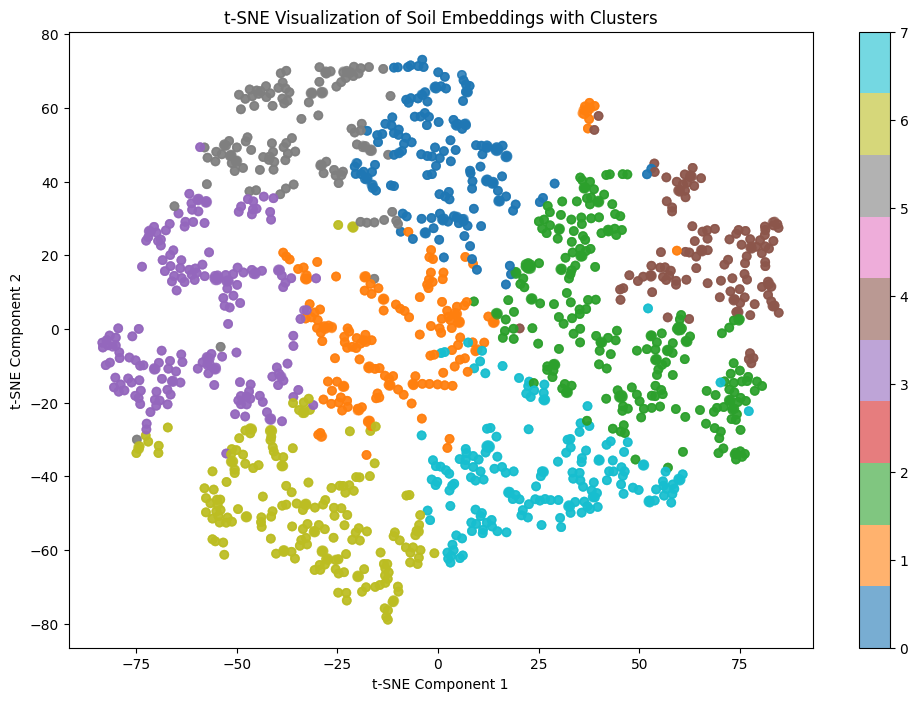


Cluster Distribution:
Cluster 0: 440 samples (11.2%)
Cluster 1: 471 samples (12.0%)
Cluster 2: 687 samples (17.5%)
Cluster 3: 557 samples (14.2%)
Cluster 4: 339 samples (8.7%)
Cluster 5: 348 samples (8.9%)
Cluster 6: 561 samples (14.3%)
Cluster 7: 513 samples (13.1%)

Cluster Geographic Statistics:
Cluster 0: Lat range: 8.23°, Lon range: 10.48°
Cluster 1: Lat range: 9.37°, Lon range: 24.64°
Cluster 2: Lat range: 8.49°, Lon range: 15.20°
Cluster 3: Lat range: 12.63°, Lon range: 29.05°
Cluster 4: Lat range: 7.22°, Lon range: 15.36°
Cluster 5: Lat range: 8.34°, Lon range: 17.29°
Cluster 6: Lat range: 13.00°, Lon range: 26.53°
Cluster 7: Lat range: 10.26°, Lon range: 24.02°


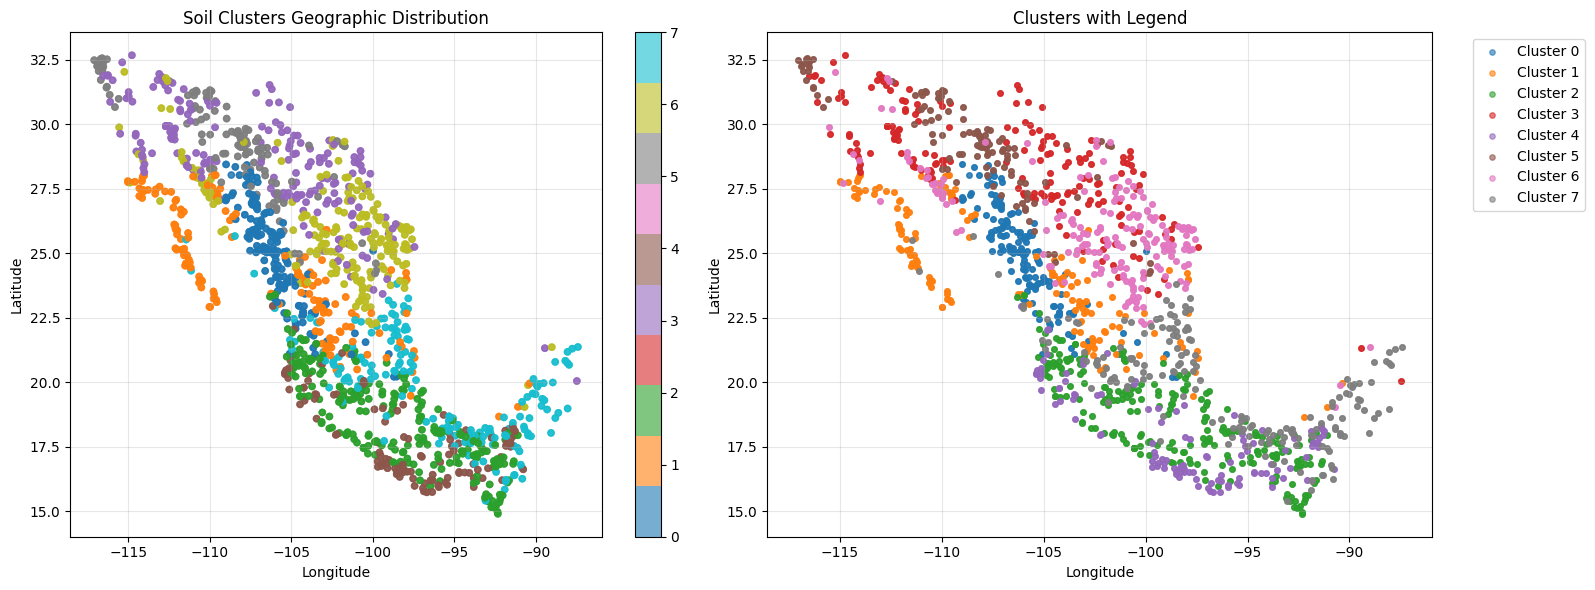


Cluster centers shape: (8, 64)

Silhouette Analysis:
k=2: Silhouette Score = 0.373
k=3: Silhouette Score = 0.335
k=4: Silhouette Score = 0.302
k=5: Silhouette Score = 0.267
k=6: Silhouette Score = 0.275
k=7: Silhouette Score = 0.259
k=8: Silhouette Score = 0.254
k=9: Silhouette Score = 0.248
k=10: Silhouette Score = 0.244
k=11: Silhouette Score = 0.239
k=12: Silhouette Score = 0.234
k=13: Silhouette Score = 0.234
k=14: Silhouette Score = 0.234


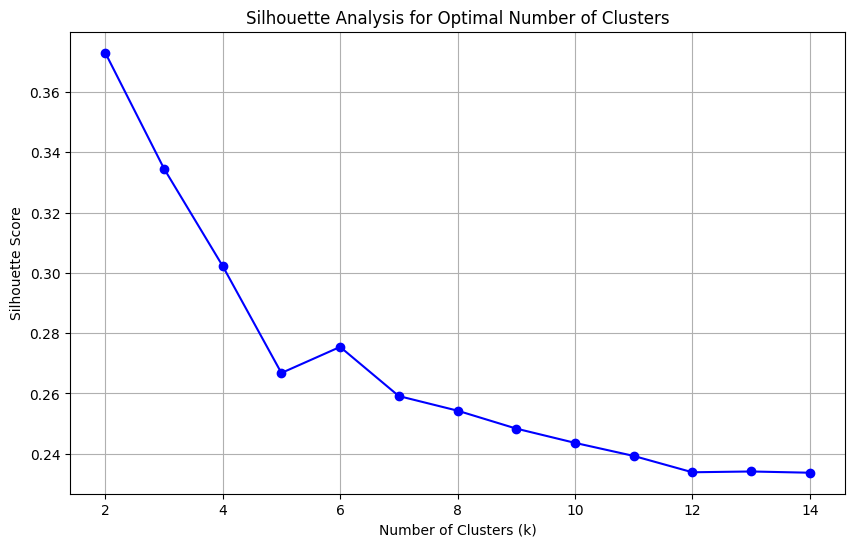


Optimal number of clusters based on silhouette score: 2


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

df_reset = df.reset_index(drop=True)

# Assuming final_embeddings is a list/array and df is your dataframe
# Convert embeddings to numpy array if needed
embeddings_array = np.array(final_embeddings)

# Perform clustering
n_clusters = 8  # Adjust based on your needs
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings_array)

# Add cluster labels to dataframe
df['cluster'] = cluster_labels

# Create a color palette for clusters
colors = px.colors.qualitative.Set3[:n_clusters]

# 1. Interactive map visualization with Plotly
fig_map = px.scatter_mapbox(
    df, 
    lat='latitude', 
    lon='longitude',
    color='cluster',
    color_discrete_sequence=colors,
    hover_data=['cluster'],
    zoom=4,
    center={"lat": 23.6345, "lon": -102.5528},  # Center of Mexico
    mapbox_style="open-street-map",
    title="Soil Embedding Clusters Across Mexico",
    height=600
)

fig_map.update_layout(
    mapbox_style="open-street-map",
    margin={"r":0,"t":50,"l":0,"b":0}
)

fig_map.show()

# 2. t-SNE visualization for embedding space
print("Computing t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
embeddings_2d = tsne.fit_transform(embeddings_array)

# Create t-SNE plot
fig_tsne = plt.figure(figsize=(12, 8))
scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                     c=cluster_labels, cmap='tab10', alpha=0.6)
plt.colorbar(scatter)
plt.title('t-SNE Visualization of Soil Embeddings with Clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()

# 3. Cluster statistics
print(f"\nCluster Distribution:")
cluster_counts = df['cluster'].value_counts().sort_index()
for cluster_id, count in cluster_counts.items():
    print(f"Cluster {cluster_id}: {count} samples ({count/len(df)*100:.1f}%)")

# 4. Geographic spread analysis
print(f"\nCluster Geographic Statistics:")
for cluster_id in range(n_clusters):
    cluster_data = df[df['cluster'] == cluster_id]
    lat_range = cluster_data['latitude'].max() - cluster_data['latitude'].min()
    lon_range = cluster_data['longitude'].max() - cluster_data['longitude'].min()
    print(f"Cluster {cluster_id}: Lat range: {lat_range:.2f}°, Lon range: {lon_range:.2f}°")

# 5. Alternative: Static map with matplotlib and basemap-like visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot of coordinates colored by cluster
scatter = ax1.scatter(df['longitude'], df['latitude'], 
                     c=df['cluster'], cmap='tab10', alpha=0.6, s=20)
ax1.set_xlabel('Longitude')
ax1.set_ylabel('Latitude')
ax1.set_title('Soil Clusters Geographic Distribution')
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax1)

# Density plot by cluster
for cluster_id in range(n_clusters):
    cluster_data = df[df['cluster'] == cluster_id]
    ax2.scatter(cluster_data['longitude'], cluster_data['latitude'], 
               label=f'Cluster {cluster_id}', alpha=0.6, s=15)

ax2.set_xlabel('Longitude')
ax2.set_ylabel('Latitude')
ax2.set_title('Clusters with Legend')
ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 6. Cluster centers analysis
cluster_centers = kmeans.cluster_centers_
print(f"\nCluster centers shape: {cluster_centers.shape}")

# Find representative samples for each cluster (closest to centroid)
# from sklearn.metrics.pairwise import euclidean_distances

# representative_samples = []
# for i, center in enumerate(cluster_centers):
#     cluster_mask = cluster_labels == i
#     cluster_embeddings = embeddings_array[cluster_mask]
#     cluster_indices = np.where(cluster_mask)[0]
    
#     # Find closest sample to cluster center
#     distances = euclidean_distances([center], cluster_embeddings)[0]
#     closest_idx = cluster_indices[np.argmin(distances)]
#     representative_samples.append(closest_idx)
    
#     print(f"Cluster {i} representative sample index: {closest_idx}")
#     print(f"  Location: ({df.loc[closest_idx, 'latitude']:.3f}, {df.loc[closest_idx, 'longitude']:.3f})")

# 7. Optional: Silhouette analysis for optimal number of clusters
from sklearn.metrics import silhouette_score

print(f"\nSilhouette Analysis:")
silhouette_scores = []
k_range = range(2, min(15, len(df)//10))  # Reasonable range based on data size

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(embeddings_array)
    score = silhouette_score(embeddings_array, labels_temp)
    silhouette_scores.append(score)
    print(f"k={k}: Silhouette Score = {score:.3f}")

# Plot silhouette scores
plt.figure(figsize=(10, 6))
plt.plot(k_range, silhouette_scores, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis for Optimal Number of Clusters')
plt.grid(True)
plt.show()

optimal_k = k_range[np.argmax(silhouette_scores)]
print(f"\nOptimal number of clusters based on silhouette score: {optimal_k}")

In [10]:
# get statistics per cluster
cluster_stats = df.groupby('cluster').agg({
    'sand': ['mean', 'std'],
    'elcosp': ['mean', 'std'],
    'slope': ['mean', 'std'],
    'orgc': ['mean', 'std'],
    'inorgc': ['mean', 'std'],
    'silt_clay': ['mean', 'std'],
    'phaq': ['mean', 'std'],
    'rock_fragments': ['mean', 'std'],
    'landcover': lambda x: x.mode()[0] if not x.mode().empty else np.nan,
    'bedrock': lambda x: x.mode()[0] if not x.mode().empty else np.nan,
    'soil_type': lambda x: x.mode()[0] if not x.mode().empty else np.nan,
    'ecoregion': lambda x: x.mode()[0] if not x.mode().empty else np.nan,
}).reset_index()

cluster_stats

cluster       sand               elcosp               slope            \
                mean        std      mean       std      mean       std   
0       0  53.358850  13.994844  0.087032  0.138000  5.513004  4.908628   
1       1  64.138301  14.425170  0.376867  1.163660  1.173712  1.352384   
2       2  45.304127  13.697397  0.109227  0.170688  5.556005  4.626313   
3       3  69.242262  12.913791  0.341753  0.730383  0.928388  1.167895   
4       4  72.044884  13.322423  0.093400  0.169785  2.980875  3.190602   
5       5  59.345208  13.986699  0.133536  0.240838  2.759781  2.496961   
6       6  35.595497  12.867310  1.067002  3.211105  0.607654  0.914119   
7       7  29.805935  12.391690  0.266525  0.771843  1.181563  1.524169   

        orgc                 inorgc  ...  silt_clay                 phaq  \
        mean        std        mean  ...       mean        std      mean   
0  19.497791  20.734792    1.123698  ...  46.645088  13.991611  5.781171   
1   7.392292   7.591854   82.219480  ...  35.895410  14.395154  7.828687   
2  21.765039  20.291434    4.136993  ...  54.713287  13.697319  5.515333   
3   6.396049   5.053146  215.868908  ...  30.772417  12.889595  8.390882   
4  10.771796  10.671943    0.277130  ...  27.955760  13.321625  5.783614   
5  13.421054  13.343342   45.274641  ...  40.654792  13.986699  6.651659   
6  10.996265   7.865330  231.237636  ...  64.404503  12.867310  8.347094   
7  19.699516  12.382742   64.213448  ...  70.208422  12.427621  6.556519   

            rock_fragments           landcover              bedrock  \
        std           mean       std  <lambda>             <lambda>   
0  0.617591      19.276744  6.378124       9.0  rocas_sedimentarias   
1  1.201660       8.087077  7.187445      17.0  rocas_sedimentarias   
2  0.800674       6.094092  6.010627       9.0  rocas_sedimentarias   
3  0.566602       9.545261  7.749236       7.0  rocas_sedimentarias   
4  0.774161       5.828335  6.386818       8.0  rocas_sedimentarias   
5  1.016903      20.695384  6.287678       7.0  rocas_sedimentarias   
6  0.464865       3.344622  4.179689       7.0  rocas_sedimentarias   
7  1.143036       3.140137  4.114995      10.0  rocas_sedimentarias   

         soil_type ecoregion  
          <lambda>  <lambda>  
0  REGOSOL EUTRICO       4.0  
1  REGOSOL EUTRICO       5.0  
2  REGOSOL EUTRICO       4.0  
3  XEROSOL HAPLICO       5.0  
4  REGOSOL EUTRICO       2.0  
5          LITOSOL       5.0  
6  XEROSOL CALCICO       5.0  
7  VERTISOL PELICO       1.0  

[8 rows x 21 columns]

In [11]:
cluster_stats.to_csv('cluster_statistics.csv', index=False)